# Relatedness results and saved-model inference

This notebook reads the immutable full-cohort test **aggregate**, not test targets, and performs fresh saved-model analysis on development pairs. The selected policy is fixed at 25% of the trained three-seed E5 ranking head plus 75% character overlap. No weight or model is selected here.

All 3,969 test pairs are represented. Amharic, Hausa and Kinyarwanda tests were previously observed; the six additional language targets were released once after the model/proof freeze. The pooled score is not wholly untouched.

In [1]:
from pathlib import Path
import os,sys,json,hashlib,time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic('matplotlib','inline')
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT));torch.set_num_threads(2)
ARTIFACTS=Path(os.environ.get('SEMREL_RUN',str(ROOT/'data/features')))
PROCESSED=ROOT/'data/processed/semrel-full-v3';SELECTED=ROOT/'models/selected'
FIGURES=ROOT/'assets/figures';FIGURES.mkdir(parents=True,exist_ok=True)
def report(name):return json.loads((ROOT/'docs'/name).read_text(encoding='utf-8'))
def sha(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def show(fig,name):
    fig.tight_layout(pad=1.5,w_pad=3);fig.savefig(FIGURES/name,dpi=140,bbox_inches='tight');display(fig);plt.close(fig)
final=report('final-test.json');training=report('training-results.json');proof=report('inference-proof.json');identity=report('frozen-policy.json');repro=report('reproducibility.json')
LANGUAGES=tuple(identity['languages'])
assert sha(ROOT/'docs/final-test.json')==repro['test_report_sha256']
assert final['frozen_policy_sha256']==sha(ROOT/'docs/frozen-policy.json')
assert proof['checkpoint_sha256']==identity['checkpoint_sha256']==sha(SELECTED/'selected.pt')
assert sum(row['rows'] for row in final['test']['languages'].values())==3969
print({'selected':identity['selected'],'test_pairs':3969,'saved_test_report_verified':True,'test_gold_read_by_this_notebook':False})

{'selected': 'e5/convex-0.25', 'test_pairs': 3969, 'saved_test_report_verified': True, 'test_gold_read_by_this_notebook': False}


## Complete per-language test results

Equal-language macro averages prevent larger collections from dominating the score. Punjabi remains negatively correlated even though its score improves relative to character overlap; it is neither removed nor relabeled. Indonesian rank improves slightly while its rating MAE worsens slightly.

,test_pairs,selected_Spearman,character_Spearman,selected_MAE,character_MAE,Spearman_change
language,,,,,,
afr,375,0.799616,0.770112,0.246399,0.315439,0.029504
amh,171,0.770023,0.727376,0.190211,0.241569,0.042648
arb,595,0.555764,0.502380,0.338423,0.436157,0.053383
arq,583,0.556721,0.538618,0.334315,0.447546,0.018103
ary,426,0.753907,0.631849,0.144193,0.185251,0.122058
hau,603,0.613225,0.530506,0.219708,0.251446,0.082719
ind,360,0.532230,0.525901,0.222585,0.220519,0.006329
kin,222,0.611632,0.488252,0.180407,0.224057,0.123380
pan,634,-0.170520,-0.208196,0.263831,0.306337,0.037676


{'selected_macro_Spearman': 0.5580663979071158, 'baseline_macro_Spearman': 0.5007554148212281, 'selected_macro_MAE': 0.23778580419947218, 'baseline_macro_MAE': 0.2920356411554106}


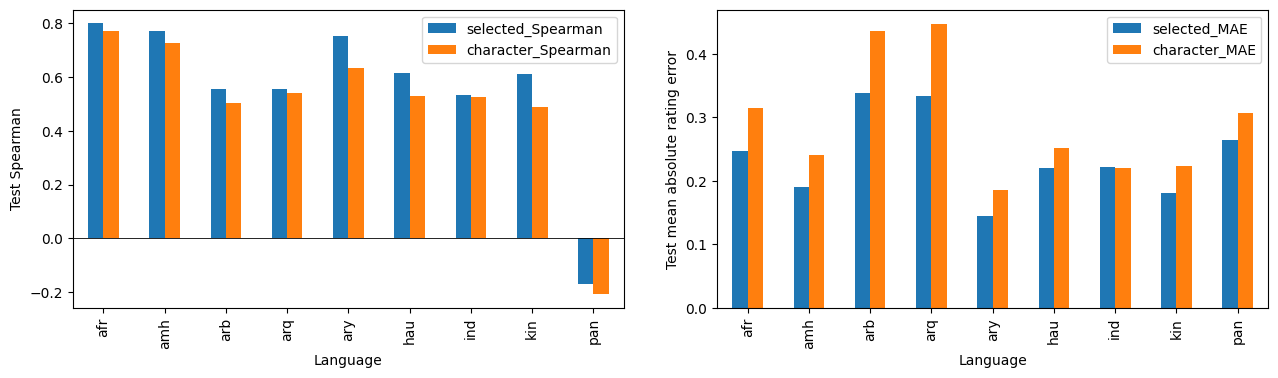

In [2]:
rows=[]
for lang in LANGUAGES:
    a,b=final['test']['languages'][lang],final['baseline']['languages'][lang]
    rows.append({'language':lang,'test_pairs':a['rows'],'selected_Spearman':a['spearman'],'character_Spearman':b['spearman'],'selected_MAE':a['mae'],'character_MAE':b['mae'],'Spearman_change':a['spearman']-b['spearman']})
test_frame=pd.DataFrame(rows).set_index('language');display(test_frame)
print({'selected_macro_Spearman':final['test']['macro_spearman'],'baseline_macro_Spearman':final['baseline']['macro_spearman'],'selected_macro_MAE':final['test']['macro_mae'],'baseline_macro_MAE':final['baseline']['macro_mae']})
fig,axes=plt.subplots(1,2,figsize=(13,4))
test_frame[['selected_Spearman','character_Spearman']].plot.bar(ax=axes[0]);axes[0].axhline(0,color='black',linewidth=.6);axes[0].set(ylabel='Test Spearman',xlabel='Language')
test_frame[['selected_MAE','character_MAE']].plot.bar(ax=axes[1]);axes[1].set(ylabel='Test mean absolute rating error',xlabel='Language')
show(fig,'sts_current_test_languages.png')

In [3]:
groups=[]
for name,group in final['test_exposure_groups'].items():
    groups.append({'test_exposure_group':name,'languages':len(group['languages']),'pairs':sum(r['rows'] for r in group['selected']['languages'].values()),'selected_macro_Spearman':group['selected']['macro_spearman'],'character_macro_Spearman':group['baseline']['macro_spearman'],'selected_macro_MAE':group['selected']['macro_mae']})
display(pd.DataFrame(groups))
assert sum(row['pairs'] for row in groups)==3969
print('Exposure groups are reported separately; the six-language comparison is not pooled with the earlier observed three for a blind-test claim.')

,test_exposure_group,languages,pairs,selected_macro_Spearman,character_macro_Spearman,selected_macro_MAE
0,previously_observed_three_languages,3,996,0.66496,0.582045,0.196775
1,six_additional_languages,6,2973,0.50462,0.460111,0.258291


Exposure groups are reported separately; the six-language comparison is not pooled with the earlier observed three for a blind-test claim.


## Conditional component uncertainty

The saved evaluation used 1,000 paired, language-stratified sentence-component resamples. These intervals describe this corpus conditional on its connected groups. Shared source sentences, unknown pretraining exposure and repeated development selection remain outside that resampling guarantee.

,requested_resamples,valid_resamples,selected_macro_interval,paired_gain_interval
0,1000,1000,"[0.5333512236470301, 0.5827225298381323]","[0.04623600764899323, 0.06943353859215586]"


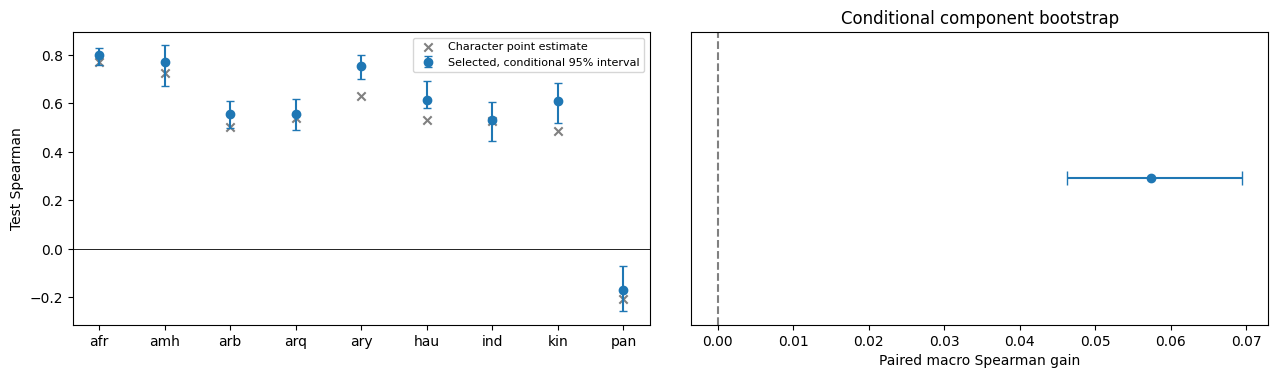

In [4]:
uncertainty=final['uncertainty']
display(pd.DataFrame([{'requested_resamples':uncertainty['requested_resamples'],'valid_resamples':uncertainty['valid_macro_resamples'],'selected_macro_interval':uncertainty['macro_spearman_95_percentile'],'paired_gain_interval':uncertainty['paired_macro_spearman_delta_95_percentile']}]))
fig,axes=plt.subplots(1,2,figsize=(13,4))
points=test_frame.selected_Spearman.to_numpy();bounds=np.asarray([uncertainty['per_language_spearman_95_percentile'][lang] for lang in LANGUAGES]);indices=np.arange(9)
axes[0].errorbar(indices,points,yerr=np.vstack((points-bounds[:,0],bounds[:,1]-points)),fmt='o',capsize=3,label='Selected, conditional 95% interval');axes[0].scatter(indices,test_frame.character_Spearman,marker='x',color='gray',label='Character point estimate');axes[0].set_xticks(indices,LANGUAGES);axes[0].axhline(0,color='black',linewidth=.6);axes[0].set(ylabel='Test Spearman');axes[0].legend(fontsize=8)
gain=final['test']['macro_spearman']-final['baseline']['macro_spearman'];low,high=uncertainty['paired_macro_spearman_delta_95_percentile']
axes[1].errorbar([gain],[0],xerr=[[gain-low],[high-gain]],fmt='o',capsize=5);axes[1].axvline(0,color='gray',linestyle='--');axes[1].set(xlabel='Paired macro Spearman gain',yticks=[],title='Conditional component bootstrap')
show(fig,'sts_current_component_uncertainty.png')

## Fresh development error analysis

The following calculations load real saved development features and trained weights. They do not use test labels or refit the model. Error bins and language means show where a positive rank gain still leaves biased rating scores.

,pairs,mean_human_rating,mean_prediction,selected_MAE,character_MAE
rating_bin,,,,,
"(-0.001, 0.2]",179,0.107654,0.263574,0.199550,0.190224
"(0.2, 0.4]",274,0.301898,0.264938,0.135677,0.161218
"(0.4, 0.6]",421,0.498599,0.331741,0.196425,0.260083
"(0.6, 0.8]",316,0.692532,0.385984,0.312493,0.385749
"(0.8, 1.0]",157,0.899936,0.484661,0.417937,0.489848


,pairs,mean_signed_error,selected_MAE,character_MAE
language,,,,
afr,375,-0.241708,0.245961,0.311648
amh,95,-0.173569,0.186498,0.235435
arb,32,-0.288515,0.301250,0.388551
arq,97,-0.317476,0.317476,0.429818
ary,71,-0.099243,0.142189,0.182505
hau,212,-0.157944,0.220357,0.252525
ind,144,0.048167,0.230833,0.235055
kin,79,-0.115337,0.221897,0.248646
pan,242,-0.101935,0.256135,0.302386


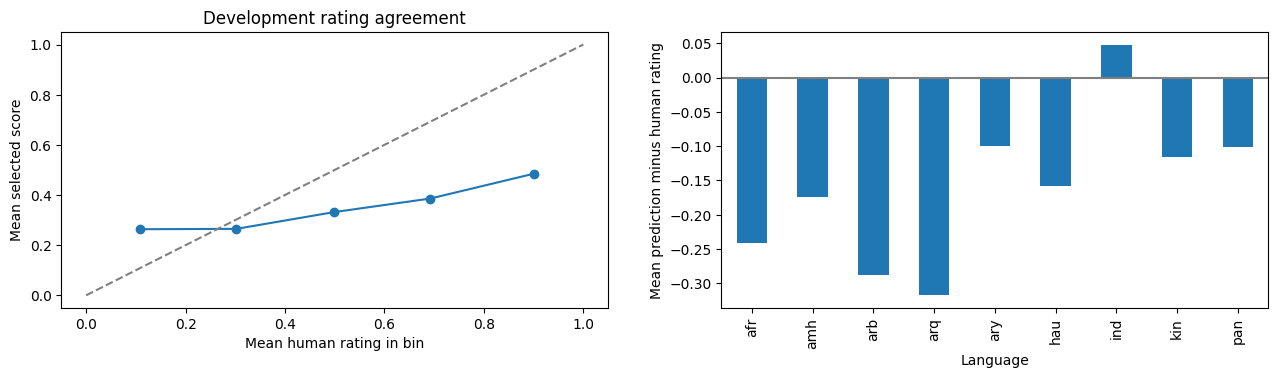

In [5]:
from src.models.full_inference import load_split,predict_features,validate_bundle
from src.models.train import Head
from src.features.build_features import scale,pair_features
vx,vy,vl,rows,receipt=load_split(ARTIFACTS/'embeddings-e5',PROCESSED,'dev')
bundle=torch.load(SELECTED/'selected.pt',map_location='cpu',weights_only=True);validate_bundle(bundle)
baseline=torch.load(SELECTED/'baseline.pt',map_location='cpu',weights_only=True)
prediction=predict_features(bundle,vx);reference=predict_features(baseline,vx)
errors=pd.DataFrame({'language':vl,'target':vy,'selected':prediction,'character':reference})
errors['selected_error']=errors.selected-errors.target;errors['character_error']=errors.character-errors.target
errors['rating_bin']=pd.cut(errors.target,np.linspace(0,1,6),include_lowest=True)
binned=errors.groupby('rating_bin',observed=True).agg(pairs=('target','size'),mean_human_rating=('target','mean'),mean_prediction=('selected','mean'),selected_MAE=('selected_error',lambda x:abs(x).mean()),character_MAE=('character_error',lambda x:abs(x).mean()))
display(binned)
language_errors=errors.groupby('language').agg(pairs=('target','size'),mean_signed_error=('selected_error','mean'),selected_MAE=('selected_error',lambda x:abs(x).mean()),character_MAE=('character_error',lambda x:abs(x).mean()))
display(language_errors)
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].plot(binned.mean_human_rating,binned.mean_prediction,marker='o');axes[0].plot([0,1],[0,1],color='gray',linestyle='--');axes[0].set(xlabel='Mean human rating in bin',ylabel='Mean selected score',title='Development rating agreement')
language_errors.mean_signed_error.reindex(LANGUAGES).plot.bar(ax=axes[1]);axes[1].axhline(0,color='gray');axes[1].set(xlabel='Language',ylabel='Mean prediction minus human rating')
show(fig,'sts_current_validation_errors.png')

## Trained-seed variation

All three heads were genuinely trained on the same full training cohort with different seeds. Their prediction spread is a model diagnostic, not a confidence interval for a new sentence pair. The global character prior reduces this spread by the fixed factor 0.25.

,development_pairs,mean_head_seed_SD,mean_selected_seed_SD
language,,,
afr,375,0.033627,0.008407
amh,95,0.032028,0.008007
arb,32,0.033853,0.008463
arq,97,0.038868,0.009717
ary,71,0.036459,0.009115
hau,212,0.035787,0.008947
ind,144,0.033664,0.008416
kin,79,0.040089,0.010022
pan,242,0.035465,0.008866


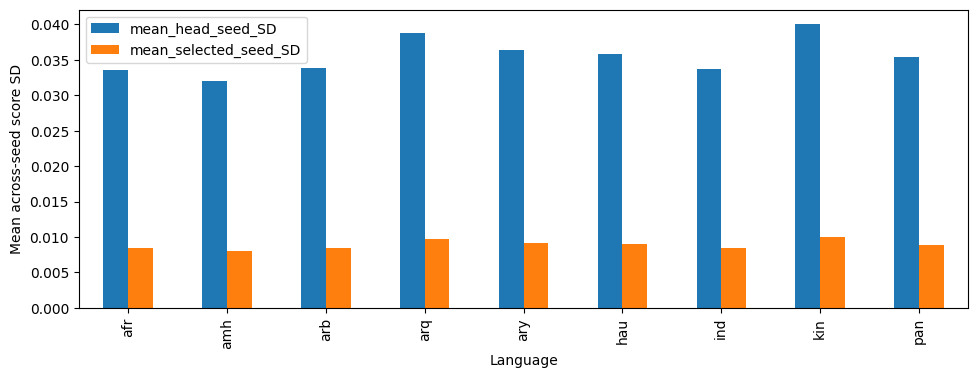

In [6]:
component=bundle['component'];normalized=scale(vx,component['mean'],component['std']);seed_scores=[]
for saved in component['components']:
    head=Head(1539,128,saved['config']['dropout']);head.load_state_dict(saved['state_dict']);head.eval()
    with torch.inference_mode():seed_scores.append(head(torch.from_numpy(normalized)).numpy())
seed_scores=np.asarray(seed_scores);spread=seed_scores.std(axis=0)
seed_frame=pd.DataFrame([{'language':lang,'development_pairs':int((vl==lang).sum()),'mean_head_seed_SD':float(spread[vl==lang].mean()),'mean_selected_seed_SD':float((.25*spread[vl==lang]).mean())} for lang in LANGUAGES]).set_index('language')
display(seed_frame)
assert np.max(abs(prediction-(.75*vx[:,-1]+.25*seed_scores.mean(axis=0))))==0
fig,ax=plt.subplots(figsize=(10,4));seed_frame[['mean_head_seed_SD','mean_selected_seed_SD']].plot.bar(ax=ax);ax.set(xlabel='Language',ylabel='Mean across-seed score SD');show(fig,'sts_current_seed_variation.png')

## Actual text proof and local checkpoint replay

The pinned E5 encoder was run on nine actual development pairs and their reversals in a private CPU job. The table below is that measured cloud proof, not a claim that this notebook allocated an encoder. Local cached inference and reload are executed here on the same selected checkpoint. Source news text and model weights stay private.

In [7]:
display(pd.DataFrame([{'real_text_rows':proof['rows'],'actual_text_cache_max_difference':proof['actual_text_vs_cache_max_difference'],'reversal_max_difference':proof['reversal_max_difference'],'truncated_sentences':proof['tokenization']['truncated_sentences'],'cloud_CPU_seconds':proof['seconds'],'missing_backbone_keys':len(proof['encoder']['loading']['missing_keys']),'mismatched_backbone_keys':len(proof['encoder']['loading']['mismatched_keys'])}]))
indices=[next(i for i,row in enumerate(rows) if row['language']==lang) for lang in LANGUAGES]
with np.load(ARTIFACTS/'embeddings-e5/dev.npz',allow_pickle=False) as data:embeddings=data['embeddings'][indices]
reverse_rows=[{**rows[i],'sentence1':rows[i]['sentence2'],'sentence2':rows[i]['sentence1']} for i in indices]
reverse_features=pair_features(embeddings[:,::-1],reverse_rows)
forward=predict_features(bundle,vx[indices]);reverse=predict_features(bundle,reverse_features)
reloaded=torch.load(SELECTED/'selected.pt',map_location='cpu',weights_only=True)
reload_difference=float(np.max(abs(predict_features(reloaded,vx[indices])-forward)))
reversal_difference=float(np.max(abs(forward-reverse)))
assert reload_difference==0 and reversal_difference==0
display(pd.DataFrame({'language':LANGUAGES,'actual_cached_score':forward,'reverse_score':reverse}))
print({'saved_reload_max_difference':reload_difference,'cached_reversal_max_difference':reversal_difference,'score_is_calibrated_probability':False})

,real_text_rows,actual_text_cache_max_difference,reversal_max_difference,truncated_sentences,cloud_CPU_seconds,missing_backbone_keys,mismatched_backbone_keys
0,18,1.788139e-07,0.0,0,80.197351,0,0


,language,actual_cached_score,reverse_score
0,afr,0.304191,0.304191
1,amh,0.656580,0.656580
2,arb,0.096641,0.096641
3,arq,0.206434,0.206434
4,ary,0.409577,0.409577
5,hau,0.280375,0.280375
6,ind,0.356880,0.356880
7,kin,0.337259,0.337259
8,pan,0.295813,0.295813


{'saved_reload_max_difference': 0.0, 'cached_reversal_max_difference': 0.0, 'score_is_calibrated_probability': False}


For raw text, `python -m src.models.full_inference --checkpoint models/selected/selected.pt --input data/my-real-pairs.jsonl --output data/my-new-scores.json` runs the pinned encoder and scorer. Use two nonempty sentence fields; prediction does not consume labels. Encoder work needs adequate RAM; it was measured on cloud CPU. The scorer remains weak for Punjabi and is not a calibrated probability or a guarantee of transfer to independent sources.